# XFEL weighted $2mF_o-DF_c$ electron density map

This notebook builds the **weighted $2F_o-F_c$ electron-density map** for one structure, sharpens it by a $B$-factor $\Delta B$, extracts a fragment around a site of interest, and draws sigma isosurfaces in PyMOL with parts of the model superimposed.

The map is **not** a difference map. It is the Fourier transform of the deposited validation coefficients `FWT` / `PHWT` ($2m|F_o|-D|F_c|$, phase $\varphi_c$). Positive density that covers the model is the expected signal.

The default example is the Ibrahim *et al.* (Science, 2020) photosystem II 2F structure `6w1v`.

| File | Typical name | Role |
| --- | --- | --- |
| Coordinates | `{pdbid}.pdb` | model drawn on the map; also the `extends` mask |
| Structure factors | `{pdbid}-sf.cif` | deposited reflections. With `RESOLUTION_SOURCE = "sf"`, `LOWRES` and `DMIN` are the resolution range of the MTZ made from this file |
| Validation $2F_o-F_c$ coefficients | `{pdbid}_validation_2fo-fc_map_coef.cif` | `FWT` / `PHWT` that are transformed into the map |

## What the pipeline does

1. **Check** that the coordinate file, the structure-factor mmCIF, the validation coefficient file, CCP4, Coot, and PyMOL are available.
2. **Convert** both reflection files to MTZ (`cif2mtz`) and **report** their resolution limits.
3. **Sharpen and Fourier-transform** `FWT` / `PHWT` (`fft` with `SCALE F1 1 ΔB`) inside `LOWRES`–`DMIN`, then **extend** the map around the model (`extends`).
4. **Export** a radius-limited map fragment around the chosen site with headless Coot. The fragment is stored as a regular map, not a difference map.
5. **Contour** that fragment at the requested $\sigma$ levels in PyMOL, **superimpose** `SITE_CHAIN` / `SITE_RESI` and `EXTRA_RESIDUES`, **save a PNG**, and **display it in this notebook**.

## Background

The wwPDB validation coefficient file stores the EDS weighted map

$$
\rho_{2mF_o-DF_c}(\mathbf{r}) \;\propto\; \sum_{hkl} F_{\mathrm{WT}}\, e^{i\varphi_{\mathrm{WT}}}\, e^{-2\pi i \mathbf{h}\cdot\mathbf{r}},
$$

where $F_{\mathrm{WT}}$ (`FWT`) is already $2m|F_o|-D|F_c|$ and $\varphi_{\mathrm{WT}}$ (`PHWT`) is the model phase. The companion `FOM` column is the figure of merit that went into that weighting. It is **not** applied a second time.

**Sharpening.** Before the transform, CCP4 `fft` rescales each amplitude with

$$
F_{\mathrm{used}} = F_{\mathrm{WT}}\,\exp\!\big(-\Delta B\,(\sin\theta/\lambda)^2\big).
$$

$\Delta B$ is the `SCALE F1` temperature factor. The default $\Delta B = -40\,\mathrm{\AA}^2$ makes the exponent positive at higher resolution, so those terms are boosted and the map looks sharper. The same factor is $\exp(+B_{\mathrm{sharpen}}(\sin\theta/\lambda)^2)$ with $B_{\mathrm{sharpen}} = -\Delta B$ (40 Å$^2$ in the default). $\Delta B = 0$ leaves `FWT` unchanged. $\sigma$ levels below are measured on this sharpened map.

**How to read the figure**

- Mesh sitting on atoms is accounted-for electron density.
- A gap on an atom, or a blob with no atom, is the usual $2mF_o-DF_c$ hint that the model and the data disagree. This notebook does not draw the $mF_o-DF_c$ difference map; use `XFEL_fo-fc_map_fig2.ipynb` for that.
- $2F_o-F_c$ maps are normally viewed near $1\sigma$. Levels of $3$–$5\sigma$ are for difference maps and will usually leave this mesh empty.

**Files you need**

| File | Typical name | Where to get it |
| --- | --- | --- |
| Coordinates | `{pdbid}.pdb` | [RCSB](https://www.rcsb.org) coordinates |
| Structure factors | `{pdbid}-sf.cif` | RCSB → structure factors (mmCIF) |
| Validation $2F_o-F_c$ map coefficients | `{pdbid}_validation_2fo-fc_map_coef.cif` | RCSB validation report, or `https://files.rcsb.org/pub/pdb/validation_reports/xx/{pdbid}/{pdbid}_validation_2fo-fc_map_coef.cif.gz` |

## How to choose parameters

Edit the **configuration cell** below. Everything downstream reads from that cell; you should not need to edit the CCP4/Coot/PyMOL code.

### Structure and files

- `PDB_ID` is a short label used in output names. It does not have to be a PDB code.
- If you leave a path as `None`, it is built from the naming convention above inside `INPUT_DIR`.
- Override any path when your files are named differently. Both `.pdb` and `.cif` coordinates are accepted by `extends` and by PyMOL.

### Sharpening (`DELTA_B`)

- `DELTA_B = -40.0` is $-40\,\mathrm{\AA}^2$. More negative values sharpen more.
- The output map name includes this value, so a new $\Delta B$ is not silently reused from an older file.
- Set `RECOMPUTE_MAP = True` after changing `DELTA_B` or the resolution cutoffs. The map file name includes both, so a new choice is not reused from an older file.

### Resolution (`RESOLUTION_SOURCE`, `LOWRES`, `DMIN`)

- `RESOLUTION_SOURCE = "sf"` takes `LOWRES` and `DMIN` from the structure-factor **MTZ** after `cif2mtz`. `mtzdump` reports the resolution range of the reflections. The mmCIF often does not contain `pdbx_d_res_low` / `pdbx_d_res_high`.
- `RESOLUTION_SOURCE = "explicit"` ignores that range and uses the `LOWRES` and `DMIN` numbers in the configuration cell.
- `DMIN` should be **no finer than the high-resolution limit of `FWT`**. The map cell prints that limit. The `6w1v` coefficients stop at about 2.09 Å.

### Site of interest

- `SITE_CHAIN` and `SITE_RESI` centre the Coot export and the PyMOL view. That residue is drawn as sticks and spheres.
- For **6w1v**, chain `A` residue **416** is ligand `OEY`, the major (75 %) 2F OEC conformation. Residue **415** is `OEX`, the minor conformation. Residue numbers are **not** interchangeable across PDB entries. Confirm with the residue-scan cell.
- `SITE_COPIES` may list several `(chain, resi)` pairs if you want one map fragment per monomer. The figure is drawn for the first entry.
- `EXTRA_RESIDUES` are neighbouring amino acids drawn as sticks on the same map (D1-Glu189 in the default example). An empty list is fine.
- `SITE_LABEL` is only used in file names (`OEC`, `heme`, `chromophore`, …).

### $\sigma$ isosurfaces

- `SIGMA_LEVELS = [1.0, 1.5, 2.5]` draws three nested isosurfaces of the sharpened $2mF_o-DF_c$ map.
- Use a single value, e.g. `[1.2]`, for a cleaner image. A negative number in the list is contoured as well and coloured red; the default list is positive only.
- `surface_representation = "mesh"` (default) draws a wireframe (`isomesh`). `"solid"` draws a transparent surface (`isosurface`).
- `CONTOUR_MODE = "sigma"` (default) lets PyMOL normalise the CCP4 map to RMS = 1, so a level of `1.5` **is** $1.5\sigma$ of the sharpened map. `"absolute"` turns that normalisation off and treats the numbers as raw map units.

### Map fragment

- `EXPORT_RADIUS_A` (default 10 Å) is the Coot clip radius around the site centroid.
- `CARVE_A` (default 3 Å) hides mesh that is farther than this from the displayed atoms.
- `MAP_BORDER_A` (default 5 Å) is the `extends` padding around the coordinates.

### Re-runs

- `RECOMPUTE_MAP = False` reuses an existing extended CCP4 map for this `PDB_ID` and `DELTA_B`.
- `RECOMPUTE_FRAGMENT = False` reuses an existing Coot `.map` clip.
- PyMOL is always re-run so that contour, colour, and camera changes are cheap to iterate.
- `INSPECT_IN_PYMOL = True` opens that scene in the PyMOL GUI after the PNG is shown. Quit PyMOL after moving the camera; the notebook stores the view and redraws the figure.

In [12]:
from __future__ import annotations

import math
import os
import re
import shutil
import subprocess
import sys
from pathlib import Path

try:
    from IPython.display import Image, Markdown, display
except ImportError:  # running as a plain script rather than a notebook
    def display(obj=None, **kwargs):
        print(getattr(obj, "data", obj))

    class Image:  # noqa: N801
        def __init__(self, filename=None, width=None):
            self.filename = filename

        def __repr__(self):
            return f"[image {self.filename}]"

    class Markdown:  # noqa: N801
        def __init__(self, data=""):
            self.data = data

        def __repr__(self):
            return str(self.data)

# ---------------------------------------------------------------------------
# Configuration — edit this cell for a new structure
# ---------------------------------------------------------------------------

NOTEBOOK_DIR = Path.cwd().resolve()

PDB_ID = "9z35"
print(f"Structure: {PDB_ID}")
print(f"INPUT DIRECTORY: {INPUT_DIR}")

INPUT_DIR = NOTEBOOK_DIR / "data" / PDB_ID
OUTPUT_DIR = NOTEBOOK_DIR / f"work-2fofc-{PDB_ID}"
print(f"OUTPUT DIRECTORY: {OUTPUT_DIR}")

# Leave a path at None to use the standard RCSB-style name inside INPUT_DIR.
PDB_XYZ = None          # {pdbid}.pdb
PDB_SF = None           # {pdbid}-sf.cif
PDB_VALIDATION = None   # {pdbid}_validation_2fo-fc_map_coef.cif

CCP4_ROOT = Path("/Applications/ccp4-9")

# Isotropic sharpening passed to fft as SCALE F1 1 DELTA_B.
# F_used = FWT * exp(-DELTA_B * (sinθ/λ)^2). Negative ΔB sharpens.
DELTA_B = -40.0         # Å^2
print(f"Map sharpening ΔB: {DELTA_B:.1f} Å^2")

# Resolution cutoffs for fft, in Å.
# "sf" reads the range from the structure-factor MTZ after cif2mtz (mtzdump).
# The mmCIF often has no pdbx_d_res_low / pdbx_d_res_high.
# "explicit" uses the LOWRES and DMIN numbers below and ignores the MTZ range.
RESOLUTION_SOURCE = "sf"  # "sf" or "explicit"
LOWRES = 30.0              # explicit low-resolution cutoff (Å); ignored when SOURCE is "sf"
DMIN = 2.09                # explicit high-resolution cutoff (Å); ignored when SOURCE is "sf"

if RESOLUTION_SOURCE == "explicit":
    LOWRES = float(LOWRES)
    DMIN = float(DMIN)
    if not (LOWRES > DMIN > 0):
        raise ValueError(f"Expected LOWRES > DMIN > 0, got {LOWRES} and {DMIN}")
    print(f"Explicit resolution: low {LOWRES:.3f} Å, high {DMIN:.3f} Å")
elif RESOLUTION_SOURCE == "sf":
    print("Resolution cutoffs will be read from the structure-factor MTZ in the map cell.")
else:
    raise ValueError(
        "RESOLUTION_SOURCE must be 'sf' or 'explicit', "
        f"got {RESOLUTION_SOURCE!r}"
    )

MAP_BORDER_A = 5.0      # EXTENDS border around the model (Å)
print(f"Map border: {MAP_BORDER_A}")
print("Map coefficient: FWT / PHWT (weighted 2mFo-DFc) from the validation coefficient file")

SITE_CHAIN = "A"
SITE_RESI = 601         # OEY (major 2F OEC)
SITE_LABEL = "OEC"
SITE_COPIES = [         # Coot exports one fragment per entry
    (SITE_CHAIN, SITE_RESI),
]
EXTRA_RESIDUES = [      # drawn as sticks in PyMOL; empty list is fine
    {"chain": "A", "resi": 189, "label": "GLU189"},
]

EXPORT_RADIUS_A = 10.0
CARVE_A = 3.0

SIGMA_LEVELS = [2.0, 3.5]
CONTOUR_MODE = "sigma"  # "sigma" or "absolute"
surface_representation = "solid"  # "mesh" or "solid"
if surface_representation not in {"mesh", "solid"}:
    raise ValueError(
        "surface_representation must be 'mesh' or 'solid', "
        f"got {surface_representation!r}"
    )
print("Sigma levels: [" + ", ".join(f"{level:g}" for level in SIGMA_LEVELS) + "]")
print(f"Surface representation: {surface_representation}")

SHOW_OEC_BONDS = True   # Mn/Ca–O bonds if those atom names exist
DRAW_DEFAULT_OEC_DISTANCES = True

# Published 6w1v chain-A OEC camera. Set to None to auto-orient on the site.
PYMOL_VIEW = None

#PYMOL_VIEW = '''\
#-0.222551167, -0.711501896, -0.666503847,\
# 0.638767481,  0.410044461, -0.651020229,\
# 0.736502111, -0.570636272,  0.363232195,\
# 0.000000000,  0.000000000, -42.280372620,\
#-34.986000061, 39.219001770, 364.061004639,\
# 37.280372620, 47.280372620, -20.000000000'''

# Set True to open the rendered scene in the PyMOL GUI after the PNG is shown.
# Quit PyMOL when the camera looks right; the figure is redrawn and a PYMOL_VIEW
# matrix is printed so you can paste it above.
INSPECT_IN_PYMOL = True

PNG_WIDTH = 1600
PNG_HEIGHT = 800
RAY_TRACE = True

RECOMPUTE_MAP = True
RECOMPUTE_FRAGMENT = True

# Nested positive isosurfaces, lowest σ first. Negatives in SIGMA_LEVELS use NEG_COLORS.
MAP_COLORS = ["marine", "blue", "deepblue", "density"]
NEG_COLORS = ["red", "salmon", "magenta", "hotpink"]

Structure: 9z35
INPUT DIRECTORY: /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/9z35
OUTPUT DIRECTORY: /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/work-2fofc-9z35
Map sharpening ΔB: -40.0 Å^2
Resolution cutoffs will be read from the structure-factor MTZ in the map cell.
Map border: 5.0
Map coefficient: FWT / PHWT (weighted 2mFo-DFc) from the validation coefficient file
Sigma levels: [2, 3.5]
Surface representation: solid


In [5]:
# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------

def _standard_name(pdb_id: str, kind: str) -> Path:
    names = {
        "pdb": f"{pdb_id}.pdb",
        "sf": f"{pdb_id}-sf.cif",
        "validation": f"{pdb_id}_validation_2fo-fc_map_coef.cif",
    }
    return INPUT_DIR / names[kind]


def resolve_inputs() -> dict[str, Path]:
    files = {
        "pdb": Path(PDB_XYZ) if PDB_XYZ else _standard_name(PDB_ID, "pdb"),
        "sf": Path(PDB_SF) if PDB_SF else _standard_name(PDB_ID, "sf"),
        "validation": Path(PDB_VALIDATION) if PDB_VALIDATION else _standard_name(PDB_ID, "validation"),
    }
    return {k: v.expanduser().resolve() for k, v in files.items()}


def require_files(files: dict[str, Path]) -> None:
    missing = [f"{k}: {p}" for k, p in files.items() if not p.is_file() or p.stat().st_size == 0]
    if missing:
        raise FileNotFoundError(
            "Missing or empty input files:\n  " + "\n  ".join(missing)
        )


def delta_b_tag(value: float) -> str:
    if float(value).is_integer():
        return f"dB{int(value):+d}"
    return f"dB{value:+.1f}".replace(".", "p")


def find_ccp4(root: Path) -> Path:
    root = Path(root).expanduser()
    setup = root / "bin" / "ccp4.setup-sh"
    if not setup.is_file():
        raise FileNotFoundError(
            f"CCP4 setup script not found at {setup}. "
            "Install CCP4 or set CCP4_ROOT to the suite prefix (e.g. /Applications/ccp4-9)."
        )
    return root


def find_coot(ccp4_root: Path) -> Path:
    for candidate in (ccp4_root / "bin" / "coot", Path(shutil.which("coot") or "")):
        if candidate.is_file():
            return candidate
    raise FileNotFoundError("Coot not found. CCP4 installs it at $CCP4/bin/coot.")


def find_pymol() -> Path:
    exe = shutil.which("pymol")
    if not exe:
        raise FileNotFoundError("PyMOL not found on PATH. Install pymol (conda-forge) or add it to PATH.")
    return Path(exe)


def run_bash(script: str, log_path: Path | None = None) -> str:
    wrapped = (
        "set -eo pipefail\n"
        'export SSL_CERT_FILE="${SSL_CERT_FILE:-}"\n'
        f'source "{CCP4_ROOT}/bin/ccp4.setup-sh"\n'
        "set -eo pipefail\n"
        f'cd "{OUTPUT_DIR}"\n'
        f"{script}\n"
    )
    proc = subprocess.run(
        ["/bin/bash", "-c", wrapped],
        text=True,
        capture_output=True,
    )
    out = (proc.stdout or "") + (proc.stderr or "")
    if log_path is not None:
        log_path.write_text(out)
    if proc.returncode != 0:
        tail = out[-5000:] if out else "(no output)"
        raise RuntimeError(f"Command failed (exit {proc.returncode}):\n{script}\n\n{tail}")
    return out


def run_ccp4(program: str, kv: list[tuple[str, Path | str]], keywords: str, log_path: Path) -> str:
    parts = [program]
    for key, value in kv:
        parts.append(str(key))
        parts.append(f'"{value}"')
    body = " ".join(parts) + " << 'EOF'\n" + keywords.strip() + "\nEOF"
    print(f"→ {program}  ({log_path.name})")
    return run_bash(body, log_path)


def mtz_labels(mtz_path: Path) -> list[str]:
    text = run_ccp4("mtzdump", [("hklin", mtz_path)], "END", OUTPUT_DIR / f"{mtz_path.stem}_mtzdump.log")
    labels: list[str] = []
    capture = False
    for line in text.splitlines():
        if "Column Labels" in line:
            capture = True
            continue
        if capture:
            stripped = line.strip()
            if stripped.startswith("*") and labels:
                break
            if stripped.startswith("*"):
                continue
            labels.extend(stripped.split())
    return labels


def mtz_resolution_angstrom(mtz_path: Path) -> tuple[float, float]:
    """Return (low-resolution Å, high-resolution Å) from the mtzdump log."""
    log_path = OUTPUT_DIR / f"{mtz_path.stem}_mtzdump.log"
    text = log_path.read_text(errors="replace")
    match = re.search(
        r"Resolution Range\s*:.*?([0-9.]+)\s*-\s*([0-9.]+)\s*A",
        text,
        flags=re.S,
    )
    if not match:
        raise RuntimeError(f"Could not read resolution limits from {log_path}")
    a, b = float(match.group(1)), float(match.group(2))
    return max(a, b), min(a, b)


def pick_label(labels: list[str], candidates: list[str], what: str) -> str:
    upper = {lab.upper(): lab for lab in labels}
    for name in candidates:
        if name.upper() in upper:
            return upper[name.upper()]
    raise KeyError(
        f"No {what} column among {candidates}. MTZ labels were: {labels}"
    )


def scan_hetatm(pdb_path: Path, skip_resnames: set[str] | None = None) -> list[dict]:
    skip_resnames = skip_resnames or {"HOH", "WAT", "DOD", "H2O"}
    residues: dict[tuple, dict] = {}
    with pdb_path.open() as handle:
        for line in handle:
            if not line.startswith("HETATM"):
                continue
            resname = line[17:20].strip()
            if resname in skip_resnames:
                continue
            chain = line[21]
            try:
                resi = int(line[22:26])
            except ValueError:
                continue
            atom = line[12:16].strip()
            occ = float(line[54:60])
            key = (chain, resi, resname)
            rec = residues.setdefault(
                key, {"chain": chain, "resi": resi, "resname": resname, "atoms": set(), "occ": [occ, occ]}
            )
            rec["atoms"].add(atom)
            rec["occ"][0] = min(rec["occ"][0], occ)
            rec["occ"][1] = max(rec["occ"][1], occ)
    rows = sorted(residues.values(), key=lambda r: (r["chain"], r["resi"], r["resname"]))
    return rows


def residue_centroid(pdb_path: Path, chain: str, resi: int) -> tuple[float, float, float]:
    coords = []
    with pdb_path.open() as handle:
        for line in handle:
            if not line.startswith(("ATOM", "HETATM")):
                continue
            if line[21] != chain:
                continue
            try:
                if int(line[22:26]) != int(resi):
                    continue
            except ValueError:
                continue
            coords.append((float(line[30:38]), float(line[38:46]), float(line[46:54])))
    if not coords:
        raise ValueError(f"No atoms for chain {chain} residue {resi} in {pdb_path.name}")
    n = float(len(coords))
    return (sum(c[0] for c in coords) / n, sum(c[1] for c in coords) / n, sum(c[2] for c in coords) / n)


def residue_atom_names(pdb_path: Path, chain: str, resi: int) -> set[str]:
    names: set[str] = set()
    with pdb_path.open() as handle:
        for line in handle:
            if not line.startswith(("ATOM", "HETATM")):
                continue
            if line[21] != chain:
                continue
            try:
                if int(line[22:26]) != int(resi):
                    continue
            except ValueError:
                continue
            names.add(line[12:16].strip())
    return names


def ccp4_map_stats(path: Path) -> dict[str, float]:
    # RMS / mean / min / max of a CCP4 or Coot map file.
    import struct

    raw = path.read_bytes()
    nx, ny, nz, mode = struct.unpack_from("<4i", raw, 0)
    nsymbt = struct.unpack_from("<i", raw, 23 * 4)[0]
    if nsymbt < 0 or 1024 + nsymbt + nx * ny * nz * 4 > len(raw):
        nsymbt = 0
    if mode != 2:
        raise ValueError(f"Unsupported CCP4 map mode {mode} in {path}")
    offset = 1024 + nsymbt
    n = nx * ny * nz
    try:
        import numpy as np

        arr = np.frombuffer(raw, dtype="<f4", count=n, offset=offset)
        rms = float(np.sqrt(np.mean(np.square(arr))))
        return {
            "rms": rms,
            "mean": float(arr.mean()),
            "min": float(arr.min()),
            "max": float(arr.max()),
            "nx": float(nx),
            "ny": float(ny),
            "nz": float(nz),
        }
    except Exception:
        arr = struct.unpack_from("<" + str(n) + "f", raw, offset)
        mean = sum(arr) / float(n)
        rms = (sum(v * v for v in arr) / float(n)) ** 0.5
        return {
            "rms": float(rms),
            "mean": float(mean),
            "min": float(min(arr)),
            "max": float(max(arr)),
            "nx": float(nx),
            "ny": float(ny),
            "nz": float(nz),
        }


print(f"Notebook directory: {NOTEBOOK_DIR}")
print(f"Python: {sys.executable} ({sys.version.split()[0]})")

Notebook directory: /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook
Python: /opt/miniconda3/bin/python (3.14.7)


## 1. Check software and input files

CCP4 is expected at `/Applications/ccp4-9` (override `CCP4_ROOT` if your build lives elsewhere). Coot is taken from that CCP4 tree. PyMOL must be on `PATH` (the conda-forge `pymol` package is sufficient).

The three input files for the default example must already be in `INPUT_DIR`. The notebook does not download them.

In [6]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CCP4_ROOT = find_ccp4(CCP4_ROOT)
COOT_BIN = find_coot(CCP4_ROOT)
PYMOL_BIN = find_pymol()
FILES = resolve_inputs()
require_files(FILES)

print("CCP4 root :", CCP4_ROOT)
print("Coot      :", COOT_BIN)
print("PyMOL     :", PYMOL_BIN)
print()
print("Input files")
for key, path in FILES.items():
    print(f"  {key:18s} {path}  ({path.stat().st_size/1e6:.1f} MB)")

setup_check = run_bash('echo "CCP4=$CCP4"; which cif2mtz fft extends mtzdump')
print()
print(setup_check)

CCP4 root : /Applications/ccp4-9
Coot      : /Applications/ccp4-9/bin/coot
PyMOL     : /opt/miniconda3/bin/pymol

Input files
  pdb                /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/9z35/9z35.pdb  (5.5 MB)
  sf                 /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/9z35/9z35-sf.cif  (45.2 MB)
  validation         /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/data/9z35/9z35_validation_2fo-fc_map_coef.cif  (28.3 MB)

CCP4=/Applications/ccp4-9
/Applications/ccp4-9/bin/cif2mtz
/Applications/ccp4-9/bin/fft
/Applications/ccp4-9/bin/extends
/Applications/ccp4-9/bin/mtzdump



## 2. Inspect the coordinates and choose the site

Hetero-residues (excluding water) are listed so you can set `SITE_CHAIN` / `SITE_RESI` without guessing. For PSII look for `OEX` / `OEY` (the Mn$_4$CaO$_x$ cluster). Other systems: the chromophore, a bound ligand, a metal site, etc.

If the table is empty, the cluster may be listed as `ATOM` records — open the PDB in a text editor or in Coot and pick the residue there. Put neighbouring protein residues in `EXTRA_RESIDUES`.

In [7]:
rows = scan_hetatm(FILES["pdb"])
print(f"Non-water HETATM residues in {FILES['pdb'].name}: {len(rows)} (lipids/pigments omitted below)")
print(f"{'chain':>5} {'resi':>6} {'name':>6} {'natoms':>7} {'occ':>11}  atoms (truncated)")
print("-" * 88)
skip_names = {
    "LMT", "LHG", "SQD", "DGD", "BCR", "CLA", "CHL", "PHO",
    "STE", "LMG", "PL9", "FME", "BCT",
}
shown = 0
for rec in rows:
    flag = rec["resname"] in {"OEX", "OEY", "OEC", "MN4", "HEM", "HEC", "FE2"} or (
        rec["chain"] == SITE_CHAIN and rec["resi"] == SITE_RESI
    )
    if not flag and rec["resname"] in skip_names:
        continue
    atoms = " ".join(sorted(rec["atoms"])[:12])
    if len(rec["atoms"]) > 12:
        atoms += " …"
    occ = f"{rec['occ'][0]:.2f}-{rec['occ'][1]:.2f}"
    mark = "   <—" if flag else ""
    print(f"{rec['chain']:>5} {rec['resi']:>6d} {rec['resname']:>6} {len(rec['atoms']):>7d} {occ:>11}  {atoms}{mark}")
    shown += 1
print(f"(listed {shown} of {len(rows)} hetero-residues)")

print()
print(f"Configured site: chain {SITE_CHAIN}  residue {SITE_RESI}  label {SITE_LABEL}")
site_atoms = residue_atom_names(FILES["pdb"], SITE_CHAIN, SITE_RESI)
if not site_atoms:
    raise ValueError(
        f"Residue {SITE_CHAIN}/{SITE_RESI} was not found in {FILES['pdb'].name}. "
        "Pick a chain/residue from the table above and update SITE_CHAIN / SITE_RESI."
    )
print("Atom names at the site:", ", ".join(sorted(site_atoms)))
cx, cy, cz = residue_centroid(FILES["pdb"], SITE_CHAIN, SITE_RESI)
print(f"Centroid: {cx:.2f} {cy:.2f} {cz:.2f} Å")
for extra in EXTRA_RESIDUES:
    extra_atoms = residue_atom_names(FILES["pdb"], extra["chain"], extra["resi"])
    if not extra_atoms:
        raise ValueError(
            f"EXTRA_RESIDUES entry {extra['chain']}/{extra['resi']} was not found in {FILES['pdb'].name}."
        )
    lab = extra.get("label", f"{extra['chain']}{extra['resi']}")
    print(f"Extra residue {lab}: chain {extra['chain']} residue {extra['resi']} ({len(extra_atoms)} atoms)")

Non-water HETATM residues in 9z35.pdb: 219 (lipids/pigments omitted below)
chain   resi   name  natoms         occ  atoms (truncated)
----------------------------------------------------------------------------------------
    A    601    OEY      11   0.65-0.65  CA1 MN1 MN2 MN3 MN4 O1 O2 O3 O4 O5 O6   <—
    A    602    OEX      10   0.35-0.35  CA1 MN1 MN2 MN3 MN4 O1 O2 O3 O4 O5   <—
    A    603    FE2       1   1.00-1.00  FE   <—
    A    604     CL       1   1.00-1.00  CL
    A    605     CL       1   1.00-1.00  CL
    F    101    HEM      43   1.00-1.00  C1A C1B C1C C1D C2A C2B C2C C2D C3A C3B C3C C3D …   <—
    V    201    HEC      43   1.00-1.00  C1A C1B C1C C1D C2A C2B C2C C2D C3A C3B C3C C3D …   <—
    a    601    OEY      11   0.65-0.65  CA1 MN1 MN2 MN3 MN4 O1 O2 O3 O4 O5 O6   <—
    a    602    OEX      10   0.35-0.35  CA1 MN1 MN2 MN3 MN4 O1 O2 O3 O4 O5   <—
    a    603    FE2       1   1.00-1.00  FE   <—
    a    604     CL       1   1.00-1.00  CL
    a    605     CL      

## 3. Build the sharpened $2mF_o-DF_c$ map with CCP4

Each CCP4 step writes a log into `OUTPUT_DIR`. Re-run with `RECOMPUTE_MAP = True` to overwrite the extended map for this `DELTA_B`.

| Step | Program | Purpose |
| --- | --- | --- |
| 3a | `cif2mtz` | structure factors → MTZ. This is done even when an extended map is reused, so the resolution range can be read |
| 3b | `mtzdump` | resolution range of that MTZ. With `RESOLUTION_SOURCE = "sf"` this becomes `LOWRES` and `DMIN`. Validation coefficients are converted here only when the map is rebuilt; the transform uses `FWT` / `PHWT` |
| 3c | `fft` | Fourier transform of `FWT` / `PHWT` inside `LOWRES`–`DMIN`, with `SCALE F1 1 ΔB` |
| 3d | `extends` | cover the model plus `MAP_BORDER_A` |

`FWT` is already $2m|F_o|-D|F_c|$. `FOM` is left unused. The structure-factor MTZ is not scaled into the map. Its resolution range is what `RESOLUTION_SOURCE = "sf"` uses for the Fourier cutoff.

In [8]:
sf_mtz = OUTPUT_DIR / f"{PDB_ID}-sf.mtz"
val_mtz = OUTPUT_DIR / f"{PDB_ID}_validation_2fo-fc_map_coef.mtz"
b_tag = delta_b_tag(DELTA_B)

#--(3a) structure factors → MTZ. The resolution range is taken from this MTZ, not from the mmCIF.
if (not sf_mtz.is_file()) or RECOMPUTE_MAP:
    run_ccp4(
        "cif2mtz",
        [("hklin", FILES["sf"]), ("hklout", sf_mtz)],
        "END",
        OUTPUT_DIR / f"{PDB_ID}_cif2mtz_sf.log",
    )

#--(3b) resolution range of the structure-factor MTZ
sf_labels = mtz_labels(sf_mtz)
sf_low, sf_high = mtz_resolution_angstrom(sf_mtz)
print(f"Structure factors {sf_mtz.name}: {sf_low:.2f}–{sf_high:.2f} Å  columns={sf_labels}")

if RESOLUTION_SOURCE == "sf":
    LOWRES, DMIN = sf_low, sf_high
    print(f"Using MTZ resolution limits: low {LOWRES:.3f} Å, high {DMIN:.3f} Å")
elif RESOLUTION_SOURCE == "explicit":
    LOWRES = float(LOWRES)
    DMIN = float(DMIN)
    print(f"Using explicit resolution: low {LOWRES:.3f} Å, high {DMIN:.3f} Å")
else:
    raise ValueError(
        "RESOLUTION_SOURCE must be 'sf' or 'explicit', "
        f"got {RESOLUTION_SOURCE!r}"
    )
if not (LOWRES > DMIN > 0):
    raise ValueError(f"Expected LOWRES > DMIN > 0, got LOWRES={LOWRES}, DMIN={DMIN}")

res_tag = f"{LOWRES:.2f}-{DMIN:.2f}".replace(".", "p")
density_map = OUTPUT_DIR / f"{PDB_ID}_2fofc_{b_tag}_{res_tag}.ccp4"
extended_map = OUTPUT_DIR / f"{PDB_ID}_2fofc_{b_tag}_{res_tag}_extended.ccp4"

if extended_map.is_file() and not RECOMPUTE_MAP:

    print(f"Reusing existing map: {extended_map}")

else:

    run_ccp4(
        "cif2mtz",
        [("hklin", FILES["validation"]), ("hklout", val_mtz)],
        "END",
        OUTPUT_DIR / f"{PDB_ID}_cif2mtz_val.log",
    )

    val_labels = mtz_labels(val_mtz)
    fwt_lab = pick_label(val_labels, ["FWT"], "FWT")
    phwt_lab = pick_label(val_labels, ["PHWT"], "PHWT")
    val_low, val_high = mtz_resolution_angstrom(val_mtz)
    print(
        f"Validation coefficients {val_mtz.name}: {val_low:.2f}–{val_high:.2f} Å  "
        f"map={fwt_lab}/{phwt_lab}  columns={val_labels}"
    )
    if DMIN + 1e-3 < val_high:
        print(
            f"WARNING: DMIN {DMIN:.2f} Å is finer than the {fwt_lab} limit {val_high:.2f} Å. "
            "Those extra shells are not in the coefficient file."
        )

    stol2 = 1.0 / (4.0 * DMIN * DMIN)
    factor = math.exp(-DELTA_B * stol2)
    print(
        f"Sharpening: {fwt_lab} *= exp(-ΔB (sinθ/λ)^2) with ΔB = {DELTA_B:.2f} Å^2"
    )
    print(f"  amplitude multiplier at {DMIN:.2f} Å = {factor:.3f}")

    #--(3c) sharpened weighted 2mFo-DFc map. This is not a difference Fourier.
    run_ccp4(
        "fft",
        [("hklin", val_mtz), ("mapout", density_map)],
        (
            f"TITLE {PDB_ID} weighted 2mFo-DFc sharpened by dB={DELTA_B:.2f}\n"
            f"RESOLUTION {LOWRES:.2f} {DMIN:.2f}\n"
            f"LABIN F1={fwt_lab} PHI={phwt_lab}\n"
            f"SCALE F1 1.0 {DELTA_B:.2f}\n"
            "END"
        ),
        OUTPUT_DIR / f"fft_{PDB_ID}_2fofc_{b_tag}.log",
    )

    #--(3d) cover the model plus MAP_BORDER_A
    run_ccp4(
        "extends",
        [("mapin", density_map), ("mapout", extended_map), ("xyzin", FILES["pdb"])],
        f"BORDER {MAP_BORDER_A:.1f}\nEND",
        OUTPUT_DIR / f"extends_{PDB_ID}_2fofc_{b_tag}.log",
    )
    print("Created:", extended_map)

print()
print(
    f"Interpretation: blue mesh is sharpened 2mFo-DFc density for {PDB_ID} "
    f"(ΔB = {DELTA_B:.1f} Å^2), not a difference map."
)

→ cif2mtz  (9z35_cif2mtz_sf.log)
→ mtzdump  (9z35-sf_mtzdump.log)
Structure factors 9z35-sf.mtz: 49.75–1.90 Å  columns=['H', 'K', 'L', 'FREE', 'I(+)', 'SIGI(+)', 'I(-)', 'SIGI(-)']
Using MTZ resolution limits: low 49.750 Å, high 1.902 Å
→ cif2mtz  (9z35_cif2mtz_val.log)
→ mtzdump  (9z35_validation_2fo-fc_map_coef_mtzdump.log)
Validation coefficients 9z35_validation_2fo-fc_map_coef.mtz: 33.83–1.93 Å  map=FWT/PHWT  columns=['H', 'K', 'L', 'FOM', 'FWT', 'PHWT']
Sharpening: FWT *= exp(-ΔB (sinθ/λ)^2) with ΔB = -40.00 Å^2
  amplitude multiplier at 1.90 Å = 15.867
→ fft  (fft_9z35_2fofc_dB-40.log)
→ extends  (extends_9z35_2fofc_dB-40.log)
Created: /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/work-2fofc-9z35/9z35_2fofc_dB-40_49p75-1p90_extended.ccp4

Interpretation: blue mesh is sharpened 2mFo-DFc density for 9z35 (ΔB = -40.0 Å^2), not a difference map.


## 4. Export a site fragment with Coot

Headless Coot (`--no-graphics --script`) loads the extended CCP4 map as a **regular** map (the difference-map flag is 0), centres on the centroid of each residue in `SITE_COPIES`, and writes a clip of radius `EXPORT_RADIUS_A`.

The $\sigma$ slider in Coot is a *display* setting; it does not change the voxel values that are exported. Contouring happens later in PyMOL. The generated script is Python-2 compatible because the CCP4 `coot` wrapper still ships a Python 2 interpreter.

In [9]:
fragment_paths: list[Path] = []
coot_script = OUTPUT_DIR / "coot_site_export.py"

copies_py = ",\n    ".join(f'("{c}", {r})' for c, r in SITE_COPIES)
coot_level = float(SIGMA_LEVELS[0]) if SIGMA_LEVELS else 1.0
coot_script.write_text(f'''#!/usr/bin/env python
import os
import sys

MAP_FILE = "{extended_map}"
PDB_FILE = "{FILES["pdb"]}"
OUT_DIR = "{OUTPUT_DIR}"
RADIUS_A = {EXPORT_RADIUS_A:.1f}
SITE_COPIES = [
    {copies_py},
]

# Second argument 0: this is a 2mFo-DFc map, not a difference map.
imol_map = read_ccp4_map(MAP_FILE, 0)
if imol_map is None or imol_map < 0:
    sys.exit("Failed to read map: %s" % MAP_FILE)
set_map_is_difference_map(imol_map, 0)
try:
    set_contour_level_in_sigma(imol_map, {coot_level:.1f})
    rmsd = map_sigma(imol_map)
    print("Map RMSD (1 sigma) = %.4f" % rmsd)
except Exception:
    rmsd = None

imol_model = read_pdb(PDB_FILE)
if imol_model is None or imol_model < 0:
    sys.exit("Failed to read coordinates: %s" % PDB_FILE)

base_name = os.path.splitext(os.path.basename(MAP_FILE))[0]
for chain_id, resno in SITE_COPIES:
    atoms = residue_info_py(imol_model, chain_id, resno, "")
    if not atoms:
        print("WARNING: residue %s/%d not found - skipping" % (chain_id, resno))
        continue
    coords = [a[2] for a in atoms]
    n = len(coords)
    x = sum(c[0] for c in coords) / float(n)
    y = sum(c[1] for c in coords) / float(n)
    z = sum(c[2] for c in coords) / float(n)
    set_rotation_centre(x, y, z)
    out_name = "%s_{SITE_LABEL}_%s%d_%dA.map" % (base_name, chain_id, resno, int(RADIUS_A))
    out_path = os.path.join(OUT_DIR, out_name)
    status = export_map_fragment(imol_map, x, y, z, RADIUS_A, out_path)
    print("Exported %s (centre %.2f %.2f %.2f, radius %.1f A) -> status %s" % (
        out_path, x, y, z, RADIUS_A, status))

print("Done.")
try:
    coot_real_exit(0)
except NameError:
    pass
''')

first_chain, first_resi = SITE_COPIES[0]
fragment = OUTPUT_DIR / (
    f"{extended_map.stem}_{SITE_LABEL}_{first_chain}{first_resi}_{int(EXPORT_RADIUS_A)}A.map"
)

if fragment.is_file() and not RECOMPUTE_FRAGMENT:
    print(f"Reusing existing fragment: {fragment}")
else:
    print("Running Coot headless…")
    env = os.environ.copy()
    env["COOT_VERBOSITY_LEVEL"] = "0"
    proc = subprocess.run(
        [str(COOT_BIN), "--no-graphics", "--script", str(coot_script)],
        cwd=str(OUTPUT_DIR),
        text=True,
        capture_output=True,
        env=env,
    )
    coot_log = OUTPUT_DIR / "coot_site_export.log"
    coot_log.write_text((proc.stdout or "") + (proc.stderr or ""))
    print(proc.stdout or "")
    if proc.returncode != 0:
        raise RuntimeError(f"Coot failed (exit {proc.returncode}). See {coot_log}")

if not fragment.is_file():
    raise FileNotFoundError(f"Expected Coot fragment was not written: {fragment}")

fragment_paths.append(fragment)
print(
    f"Map fragment of radius {EXPORT_RADIUS_A:.1f} Å centered on {SITE_LABEL} in {PDB_ID}:",
    fragment,
)

Running Coot headless…
INFO:: Using Standard CCP4 Refmac dictionary from CLIBD_MON: /Applications/ccp4-9/lib/data/monomers/
There are 249 data in /Applications/ccp4-9/lib/data/monomers/list/mon_lib_list.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/a/ALA.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/a/ASP.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/a/ASN.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/c/CYS.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/g/GLN.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/g/GLY.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/g/GLU.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/p/PHE.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/h/HIS.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/i/ILE.cif
There are 2 data in /Applications/ccp4-9/lib/data/monomers/l/LYS.cif
There are 2 data in /Applications/

## 5. Contour and render in PyMOL

PyMOL loads the coordinates and the Coot fragment, builds an isosurface at each requested $\sigma$, and writes a PNG. `surface_representation = "mesh"` uses `isomesh`. `surface_representation = "solid"` uses a transparent `isosurface`. The site residue (`SITE_CHAIN`, `SITE_RESI`) and every entry in `EXTRA_RESIDUES` are shown as sticks on top of that density. The rest of the model stays hidden.

**Colour convention (nested meshes, increasing $\sigma$)**

| lowest $\sigma$ | mid | highest $\sigma$ |
| --- | --- | --- |
| marine | blue | deepblue |

A negative level in `SIGMA_LEVELS`, if you add one, is drawn red. The default list is positive $2mF_o-DF_c$ density only.

`CARVE_A` restricts each isosurface to a skin around the displayed atoms. OEC Mn/Ca–oxo bonds are added only when those atom names exist, so the same cell is safe for a non-PSII ligand.

The generated `.pml` is saved next to the PNG. Set `INSPECT_IN_PYMOL = True` in the configuration cell and re-run the next cell to open the same scene in the PyMOL GUI, change the camera, and redraw the PNG when you quit.

Fragment file stats (raw voxels): RMS=1.09041  mean=-0.00848  min=-5.89961  max=13.36964  grid=33x33x33
Contour mode: PyMOL-normalized sigma (level n = n sigma)
Surface representation: solid (isosurface)
  2 sigma -> map_2 at 2.00000 (marine)
  3.5 sigma -> map_3p5 at 3.50000 (blue)
Wrote /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/work-2fofc-9z35/pymol_9z35_2fofc_dB-40_OEC.pml
Running PyMOL headless…
PyMOL>set normalize_ccp4_maps, 1
 Setting: normalize_ccp4_maps set to 1.
PyMOL>load /Users/souda/Documents/Projects/Batista/XFEL-tutorial/XFEL-notebook/work-2fofc-9z35/9z35_2fofc_dB-40_49p75-1p90_extended_OEC_A601_10A.map, TWOFOFC
 ObjectMapCCP4: Map Size 33 x 33 x 33
 ObjectMapCCP4: Normalizing with mean = -0.008484 and stdev = 1.090396.
 ObjectMap: Map read.  Range: -5.403 to 12.269
 Crystal: Unit Cell          117.529  222.818  308.934
 Crystal: Alpha Beta Gamma    90.000   90.000   90.000
 Crystal: RealToFrac Matrix
 Crystal:    0.0085   -0.0000   -0.0000
 Crys

**9z35** sharpened $2mF_o-DF_c$ density ($\Delta B = -40$ Å$^2$) around `OEC` A/601, extra residues GLU189, contoured at 2, 3.5 $\sigma$.

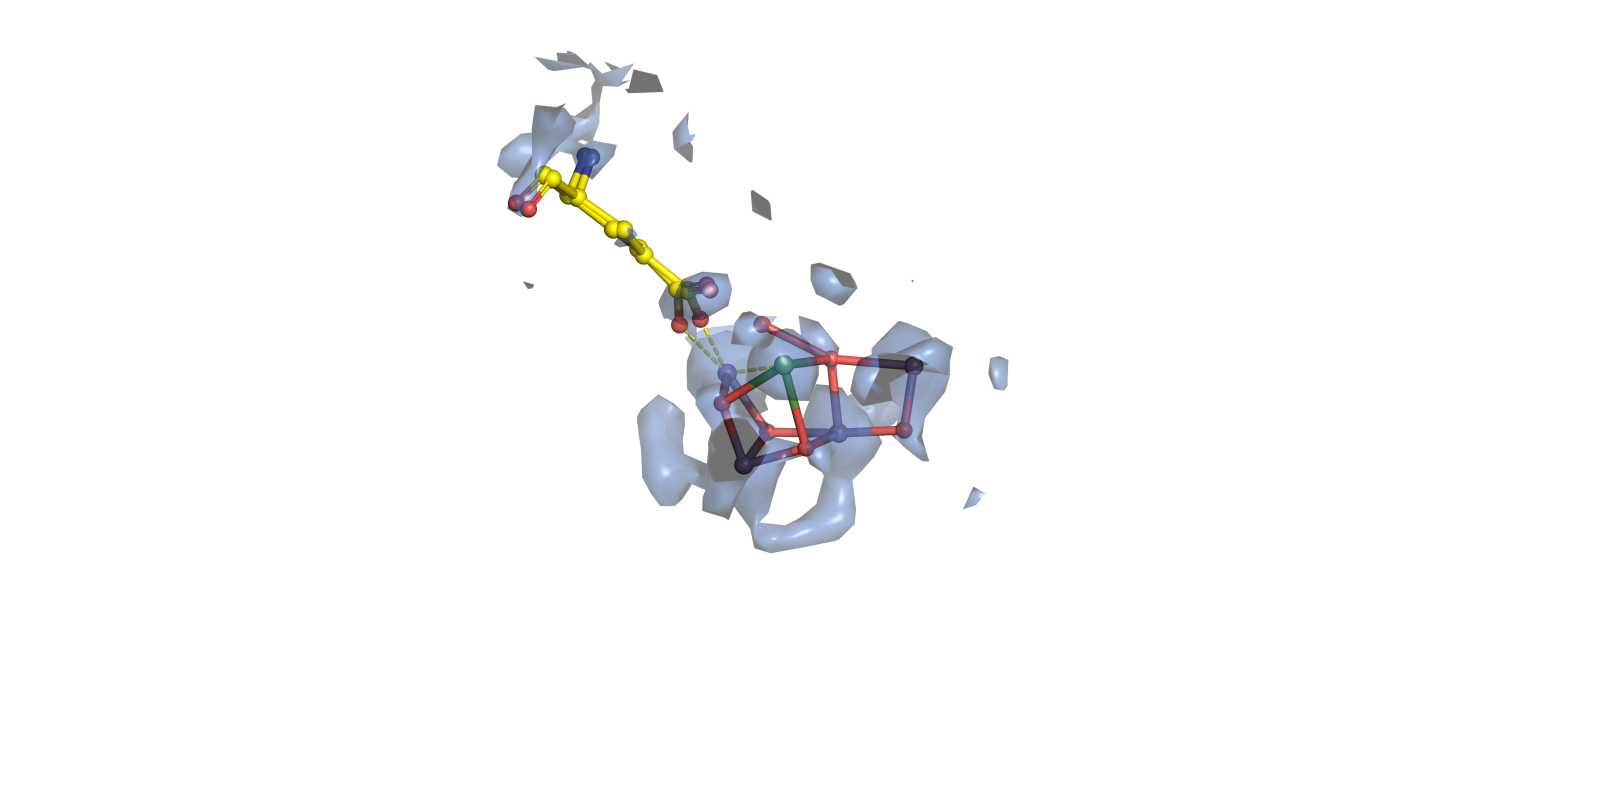

Launching PyMOL. Adjust the view, then quit the window.
 PyMOL(TM) Molecular Graphics System, Version 3.1.0.
 Copyright (c) Schrodinger, LLC.
 All Rights Reserved.
 
    Created by Warren L. DeLano, Ph.D. 
 
    PyMOL is user-supported open-source software.  Although some versions
    are freely available, PyMOL is not in the public domain.
 
    If PyMOL is helpful in your work or study, then please volunteer 
    support for our ongoing efforts to create open and affordable scientific
    software by purchasing a PyMOL Maintenance and/or Support subscription.

    More information can be found at "http://www.pymol.org".
 
    Enter "help" for a list of commands.
    Enter "help <command-name>" for information on a specific command.

 Hit ESC anytime to toggle between text and graphics.

 Detected OpenGL version 2.1. Shaders available.
 Tessellation shaders not available
 Detected GLSL version 1.20.
 OpenGL graphics engine:
  GL_VENDOR:   Apple
  GL_RENDERER: Apple M3
  GL_VERSION:  2

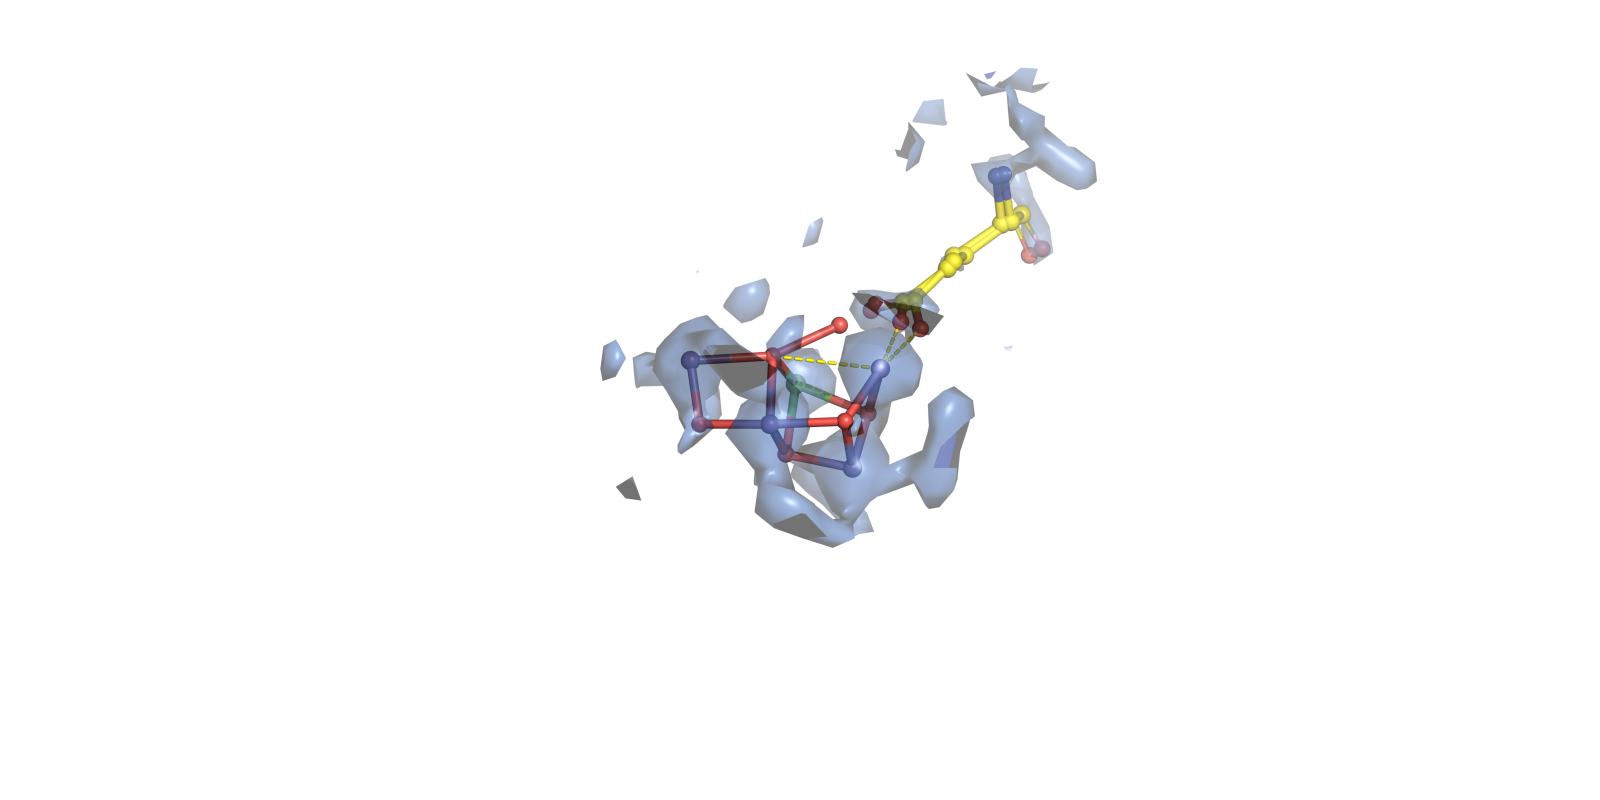

In [13]:
if not SIGMA_LEVELS:
    raise ValueError("SIGMA_LEVELS is empty. Set at least one contour in units of sigma.")

levels = [float(x) for x in SIGMA_LEVELS]
site_sel = f"xyz and chain {SITE_CHAIN} and resi {SITE_RESI}"
png_path = OUTPUT_DIR / f"{PDB_ID}_2fofc_{b_tag}_{SITE_LABEL}_{SITE_CHAIN}{SITE_RESI}.png"
pml_path = OUTPUT_DIR / f"pymol_{PDB_ID}_2fofc_{b_tag}_{SITE_LABEL}.pml"

oec_pairs = [
    ("MN1", "O1"), ("MN1", "O3"),
    ("MN2", "O1"), ("MN2", "O2"), ("MN2", "O3"),
    ("MN3", "O2"), ("MN3", "O3"), ("MN3", "O4"), ("MN3", "O5"),
    ("MN4", "O5"), ("MN4", "O4"),
    ("CA1", "O1"), ("CA1", "O2"), ("CA1", "O5"),
]

stats = ccp4_map_stats(fragment)
print(
    f"Fragment file stats (raw voxels): RMS={stats['rms']:.5f}  "
    f"mean={stats['mean']:.5f}  min={stats['min']:.5f}  max={stats['max']:.5f}  "
    f"grid={int(stats['nx'])}x{int(stats['ny'])}x{int(stats['nz'])}"
)
if CONTOUR_MODE == "sigma":
    # PyMOL normalizes CCP4 maps to mean 0 / RMS 1, so contour level n is n-sigma
    # of the sharpened map.
    contour_levels = list(levels)
    normalize_flag = 1
    print("Contour mode: PyMOL-normalized sigma (level n = n sigma)")
elif CONTOUR_MODE == "absolute":
    contour_levels = list(levels)
    normalize_flag = 0
    print("Contour mode: absolute map units (normalize_ccp4_maps off)")
else:
    raise ValueError(f"CONTOUR_MODE must be 'sigma' or 'absolute', got {CONTOUR_MODE!r}")

if surface_representation == "mesh":
    contour_cmd = "isomesh"
    surface_transparency = 0.25
elif surface_representation == "solid":
    contour_cmd = "isosurface"
    surface_transparency = 0.45
else:
    raise ValueError(
        "surface_representation must be 'mesh' or 'solid', "
        f"got {surface_representation!r}"
    )
print(f"Surface representation: {surface_representation} ({contour_cmd})")

lines: list[str] = [
    f"set normalize_ccp4_maps, {normalize_flag}",
    f"load {fragment}, TWOFOFC",
    f"load {FILES['pdb']}, xyz",
    "hide everything",
    "util.cbay xyz",
    f"select site, {site_sel}",
    "show spheres, site",
    "show sticks, site",
    "set sphere_scale, 0.15, xyz",
    "set stick_radius, 0.12, xyz",
]

for extra in EXTRA_RESIDUES:
    lab = extra.get("label", f"{extra['chain']}{extra['resi']}")
    lines += [
        f"select {lab}, xyz and chain {extra['chain']} and resi {extra['resi']}",
        f"show sticks, {lab}",
        f"show spheres, {lab}",
        f"set sphere_scale, 0.15, {lab}",
        f"set stick_radius, 0.12, {lab}",
    ]

if SHOW_OEC_BONDS:
    present = residue_atom_names(FILES["pdb"], SITE_CHAIN, SITE_RESI)
    for a, b in oec_pairs:
        if a in present and b in present:
            lines.append(f"bond site and name {a}, site and name {b}")

if DRAW_DEFAULT_OEC_DISTANCES:
    present = residue_atom_names(FILES["pdb"], SITE_CHAIN, SITE_RESI)
    if "MN1" in present and "O5" in present:
        lines.append("distance d_mn1_o5, site and name MN1, site and name O5")
    for extra in EXTRA_RESIDUES:
        extra_atoms = residue_atom_names(FILES["pdb"], extra["chain"], extra["resi"])
        if "MN1" in present and "OE2" in extra_atoms:
            lab = extra.get("label", f"{extra['chain']}{extra['resi']}")
            lines.append(
                f"distance d_mn1_{lab}_A, site and name MN1, {lab} and alt A and name OE2"
            )
            lines.append(
                f"distance d_mn1_{lab}_B, site and name MN1, {lab} and alt B and name OE2"
            )

lines += [
    "viewport %d,%d" % (PNG_WIDTH, PNG_HEIGHT),
    "bg_color white",
    "space cmyk",
    "set ray_opaque_background, 1",
    "set ray_trace_mode, 0",
    "set ray_trace_fog, 1",
    "set orthoscopic, on",
    "set antialias, 4",
    "set mesh_width, 0.25",
    "set dash_gap, 0.15",
    "set dash_radius, 0.05",
    "hide labels",
    "set auto_zoom, 0",
]

carve_target = "site"
for extra in EXTRA_RESIDUES:
    carve_target += " or " + extra.get("label", f"{extra['chain']}{extra['resi']}")
lines.append(f"select carve_sel, {carve_target}")

pos_i = 0
neg_i = 0
for level in contour_levels:
    token = f"{level:g}".replace("-", "m").replace(".", "p")
    name = f"map_{token}"
    if level >= 0:
        color = MAP_COLORS[min(pos_i, len(MAP_COLORS) - 1)]
        pos_i += 1
    else:
        color = NEG_COLORS[min(neg_i, len(NEG_COLORS) - 1)]
        neg_i += 1
    lines += [
        f"{contour_cmd} {name}, TWOFOFC, {level:.6f}, carve_sel, carve={CARVE_A:.2f}",
        f"color {color}, {name}",
    ]
    print(f"  {level:g} sigma -> {name} at {level:.5f} ({color})")
if surface_representation == "mesh":
    lines.append("set mesh_width, 0.75, map_*")
lines.append(f"set transparency, {surface_transparency:.2f}, map_*")

def pymol_camera_commands(view_numbers):
    if not view_numbers:
        return ["orient site", "zoom site, 8"]
    if len(view_numbers) != 18:
        raise ValueError(f"PyMOL view must contain 18 numbers, got {len(view_numbers)}")
    return [
        "python",
        "from pymol import cmd",
        f"cmd.set_view({tuple(float(x) for x in view_numbers)!r})",
        "python end",
    ]


def parse_pymol_view(text):
    if text is None or not str(text).strip():
        return None
    nums = [float(x) for x in re.findall(r"[-+]?(?:\d+\.?\d*|\.\d+)", str(text))]
    if len(nums) != 18:
        raise ValueError(f"PYMOL_VIEW must contain 18 numbers, got {len(nums)}")
    return nums


def format_pymol_view(nums):
    rows = [nums[i:i + 3] for i in range(0, 18, 3)]
    return ",\\\n".join(", ".join(f"{x: .9f}" for x in row) for row in rows)


def run_pymol_headless(script_lines):
    pml_path.write_text("\n".join(script_lines) + "\n")
    print("Wrote", pml_path)
    print("Running PyMOL headless…")
    proc = subprocess.run(
        [str(PYMOL_BIN), "-cq", str(pml_path)],
        cwd=str(OUTPUT_DIR),
        text=True,
        capture_output=True,
    )
    log_path = OUTPUT_DIR / "pymol_render.log"
    log_path.write_text((proc.stdout or "") + (proc.stderr or ""))
    print(proc.stdout or "")
    if proc.returncode == 0 and png_path.is_file():
        return
    # Retry without ray tracing — some macOS builds need a display for ray.
    if RAY_TRACE and any(ln.startswith("png ") and "ray=1" in ln for ln in script_lines):
        print("Ray-traced PNG failed; retrying with ray=0 …")
        fallback = [
            ln.replace("ray=1", "ray=0") if ln.startswith("png ") else ln
            for ln in script_lines
        ]
        pml_path.write_text("\n".join(fallback) + "\n")
        proc = subprocess.run(
            [str(PYMOL_BIN), "-cq", str(pml_path)],
            cwd=str(OUTPUT_DIR),
            text=True,
            capture_output=True,
        )
        log_path.write_text((proc.stdout or "") + (proc.stderr or ""))
        print(proc.stdout or "")
    if proc.returncode != 0 or not png_path.is_file():
        raise RuntimeError(f"PyMOL failed (exit {proc.returncode}). See {log_path}")


def publish_png():
    print("Saved image:", png_path)
    visible = NOTEBOOK_DIR / png_path.name
    if visible.resolve() != png_path.resolve():
        shutil.copy2(png_path, visible)
        print("Copied image:", visible)


scene_lines = list(lines)
ray_flag = 1 if RAY_TRACE else 0
png_cmd = f"png {png_path}, {PNG_WIDTH}, {PNG_HEIGHT}, dpi=200, ray={ray_flag}"
camera = pymol_camera_commands(parse_pymol_view(PYMOL_VIEW))
run_pymol_headless(scene_lines + camera + [png_cmd, "quit"])
publish_png()
sigma_txt = ", ".join(f"{s:g}" for s in levels)
extra_txt = ", ".join(
    extra.get("label", f"{extra['chain']}{extra['resi']}") for extra in EXTRA_RESIDUES
) or "none"
display(Markdown(
    f"**{PDB_ID}** sharpened $2mF_o-DF_c$ density ($\\Delta B = {DELTA_B:.0f}$ Å$^2$) around "
    f"`{SITE_LABEL}` {SITE_CHAIN}/{SITE_RESI}, extra residues {extra_txt}, "
    f"contoured at {sigma_txt} $\\sigma$."
))
display(Image(filename=str(png_path), width=min(PNG_WIDTH, 1100)))

# INSPECT_IN_PYMOL (configuration cell): open this scene in the PyMOL GUI,
# change the camera, then quit. A moved view is saved and the PNG is redrawn.
if INSPECT_IN_PYMOL:
    view_file = OUTPUT_DIR / "pymol_view.txt"
    view_file.unlink(missing_ok=True)
    inspect_pml = pml_path.with_name(pml_path.stem + "_inspect.pml")
    hook = [
        "python",
        "from pymol import cmd",
        "import threading",
        "import time",
        f"_VIEW_FILE = {str(view_file)!r}",
        "def write_view(echo=1):",
        "    view = cmd.get_view(quiet=1)",
        "    fh = open(_VIEW_FILE, 'w')",
        "    fh.write('\\n'.join('%.9f' % float(x) for x in view))",
        "    fh.close()",
        "    if int(echo):",
        "        print('Wrote PyMOL view to %s' % _VIEW_FILE)",
        "cmd.extend('write_view', write_view)",
        "def _watch_view():",
        "    initial = None",
        "    while True:",
        "        try:",
        "            view = [float(x) for x in cmd.get_view(quiet=1)]",
        "            if initial is None:",
        "                initial = view",
        "            elif max(abs(a - b) for a, b in zip(view, initial)) >= 1e-4:",
        "                write_view(0)",
        "        except Exception:",
        "            return",
        "        time.sleep(0.5)",
        "threading.Thread(target=_watch_view, daemon=True).start()",
        "print('Adjust the view, then quit PyMOL.')",
        "print('If the notebook does not pick up the camera, run write_view before quitting.')",
        "python end",
    ]
    inspect_pml.write_text("\n".join(scene_lines + camera + hook) + "\n")
    print("Launching PyMOL. Adjust the view, then quit the window.")
    proc = subprocess.run(
        [str(PYMOL_BIN), str(inspect_pml)],
        cwd=str(OUTPUT_DIR),
    )
    if proc.returncode not in (0, None):
        print(f"PyMOL exited with status {proc.returncode}.")
    if not view_file.is_file():
        print("View unchanged.")
    else:
        saved = [float(x) for x in view_file.read_text().split()]
        if len(saved) != 18:
            raise RuntimeError(f"Unexpected PyMOL view in {view_file}")
        PYMOL_VIEW = format_pymol_view(saved)
        print("Camera updated for this session. Paste this into the configuration cell to keep it:")
        print("PYMOL_VIEW = '''\\")
        print(PYMOL_VIEW)
        print("'''")
        camera = pymol_camera_commands(saved)
        png_path.unlink(missing_ok=True)
        run_pymol_headless(scene_lines + camera + [png_cmd, "quit"])
        publish_png()
        display(Image(filename=str(png_path), width=min(PNG_WIDTH, 1100)))

## Interpreting the default PSII figure

For `6w1v`, the mesh is the validation $2mF_o-DF_c$ map sharpened by $\Delta B = -40\,\mathrm{\AA}^2$, clipped around the OEC on chain A.

- The model drawn in the figure is `6w1v` itself: `OEY` A/416 as spheres and sticks, plus D1-Glu189 from `EXTRA_RESIDUES`.
- Density that wraps those atoms is the normal $2F_o-F_c$ envelope. It is not a LIGHT-minus-DARK peak.
- Contours are in units of $\sigma$ of the **sharpened** map. Raising $|\Delta B|$ changes both the features and the RMS, so a $1.5\sigma$ mesh at $-40\,\mathrm{\AA}^2$ is not the same surface as $1.5\sigma$ with no sharpening.

If the mesh is empty, lower `SIGMA_LEVELS` (try `[1.0]`). If the cage swallows the model, decrease `CARVE_A` or raise the cutoff.

## Adapting the notebook

1. Put `{pdbid}.pdb`, `{pdbid}-sf.cif`, and `{pdbid}_validation_2fo-fc_map_coef.cif` in `INPUT_DIR`, or point `PDB_XYZ`, `PDB_SF`, and `PDB_VALIDATION` at them.
2. Set `PDB_ID` and `DELTA_B`. Leave `RESOLUTION_SOURCE = "sf"` to take `LOWRES` / `DMIN` from the structure-factor MTZ, or set `RESOLUTION_SOURCE = "explicit"` and fill in those two numbers (no finer than the `FWT` limit printed in the map cell).
3. Run through the residue-scan cell, then set `SITE_CHAIN` / `SITE_RESI` / `EXTRA_RESIDUES`.
4. Set `PYMOL_VIEW = None` unless you have a camera you want to reuse.
5. Set `RECOMPUTE_MAP = True` the first time, and again whenever `DELTA_B` or the resolution cutoffs change. Afterwards leave it `False` while you tune $\sigma$ and the view.

To change the camera, set `INSPECT_IN_PYMOL = True` and re-run the render cell. Quit PyMOL when the view looks right; paste the printed matrix into `PYMOL_VIEW` to keep it. You can also open the extended map in Coot with the coordinates.